# 🚕 Q-Learning en Taxi-v4 — Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [1]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation


## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [2]:
env = gym.make("Taxi-v4", render_mode="rgb_array")

print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)


Número de estados: 500
Número de acciones: 6


### Pregunta 1

¿Cuántos estados y cuántas acciones tiene Taxi-v4?

Explique brevemente por qué Taxi tiene muchos más estados que FrozenLake.

**Respuesta.** Taxi tiene 500 estados y 6 acciones. Son muchos más que en FrozenLake porque el estado no codifica solo la posición del taxi (25 celdas), sino también la ubicación del pasajero (5 opciones, contando que vaya dentro del taxi) y su destino (4 opciones): 25 × 5 × 4 = 500. FrozenLake solo codifica la casilla del agente, así que tiene muchos menos estados.


## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [3]:
state, info = env.reset(seed=42)

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)


Estado: 386
Acción: 4
Nuevo estado: 386
Recompensa: -10
Terminated: False


### Pregunta 2

En la interacción anterior identifique:

$$
s_t,\quad a_t,\quad r_{t+1},\quad s_{t+1}
$$

¿Qué representa cada elemento?

**Respuesta.** En el código: $s_t$ es `state` (el estado inicial tras `reset`), $a_t$ es `action` (la acción aleatoria ejecutada), $r_{t+1}$ es `reward` (la recompensa recibida por esa acción) y $s_{t+1}$ es `next_state` (el estado al que pasa el taxi). Es decir, $s_t$ describe la situación actual, $a_t$ lo que hace el agente, $r_{t+1}$ qué tan buena fue esa acción y $s_{t+1}$ dónde queda el agente después.


## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [4]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]


Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3

¿Cuántos valores debe aprender el agente en total?

Calcule:

$$
|\mathcal{S}| \times |\mathcal{A}|
$$

**Respuesta.** La Q-table tiene un valor por cada par estado-acción, es decir $|\mathcal{S}| \times |\mathcal{A}| = 500 \times 6 = 3000$ valores.


## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [5]:
def choose_action(Q, state, epsilon, env):
    # Exploración: con probabilidad epsilon elegimos una acción al azar.
    if random.random() < epsilon:
        return env.action_space.sample()
    # Explotación: en otro caso elegimos la acción con mayor valor Q.
    return int(np.argmax(Q[state]))


## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [6]:
def update_q(Q, state, action, reward, next_state, alpha, gamma):
    # Target: recompensa inmediata + valor descontado del mejor Q en el siguiente estado.
    target = reward + gamma * np.max(Q[next_state])
    # Error TD y actualización de Q[state, action].
    Q[state, action] += alpha * (target - Q[state, action])
    return Q


## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [7]:
def train_q_learning(
    env,
    Q,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
):
    rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps):

            # 1: escoger acción con la política epsilon-greedy
            action = choose_action(Q, state, epsilon, env)

            # 2: ejecutar acción en el ambiente
            next_state, reward, terminated, truncated, _ = env.step(action)

            # 3: actualizar Q con la experiencia observada
            update_q(Q, state, action, reward, next_state, alpha, gamma)

            # 4: actualizar estado y recompensa acumulada
            state = next_state
            total_reward += reward

            # 5: terminar si el episodio finalizó
            if terminated or truncated:
                break

        rewards.append(total_reward)

    return Q, rewards


## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [8]:
Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)


## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


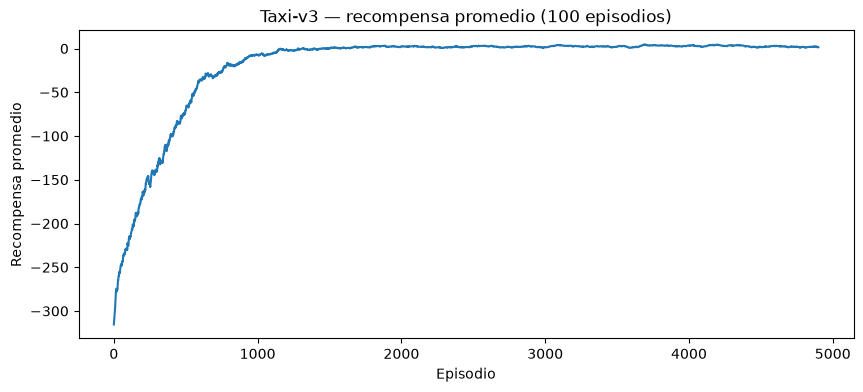

In [9]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi-v3 — recompensa promedio ({window} episodios)")
plt.show()


### Pregunta 4

Describa la curva de aprendizaje.

- ¿La recompensa promedio mejora?
- ¿Después de aproximadamente cuántos episodios comienza a estabilizarse?
- ¿El comportamiento observado indica convergencia perfecta o solamente una política razonablemente buena?

**Respuesta.** Se espera que la recompensa promedio empiece muy negativa (el taxi actúa casi al azar y acumula penalizaciones) y vaya aumentando a medida que la Q-table aprende, hasta estabilizarse en valores cercanos al óptimo del entorno. La estabilización suele apreciarse tras unos pocos miles de episodios. La curva indica una política razonablemente buena, no una convergencia perfecta: como $\epsilon > 0$, el agente sigue explorando y la media se mantiene con pequeñas oscilaciones.


## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [10]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward


def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [11]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)


Recompensa total sin entrenamiento: -248


Ahora observe el agente entrenado.


In [12]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)


Recompensa total después del entrenamiento: 10


### Pregunta 5

Compare los dos episodios.

- ¿Qué diferencias observa en el comportamiento del taxi?
- ¿El taxi sin entrenamiento logra completar la tarea?
- ¿El agente entrenado evita acciones innecesarias?
- ¿Qué evidencia visual le permite afirmar que el agente aprendió?

**Respuesta.** El taxi sin entrenar se mueve sin rumbo, da vueltas e intenta pickup/dropoff en lugares incorrectos, por lo que normalmente no completa la tarea dentro del límite de pasos y acumula recompensa muy negativa. El agente entrenado va directo a recoger al pasajero y luego a su destino, con pocos movimientos y sin acciones inútiles, logrando una recompensa total claramente mayor. La evidencia visual es ese recorrido corto y dirigido que termina con el dropoff correcto, frente al movimiento errático del taxi sin entrenar.


## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [13]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))


Estado: 123
Q-values: [-2.06283741 -0.89488866 -2.14892179  3.94947757 -6.32477285 -5.05016419]
Mejor acción: 3


### Pregunta 6

Para el estado seleccionado:

1. ¿Cuál es la acción con mayor valor Q?
2. ¿Qué significa que una acción tenga un valor Q mayor que otra?
3. ¿Por qué no podemos interpretar $Q(s,a)$ únicamente como la recompensa inmediata de ejecutar la acción?

**Respuesta.** 1. La acción con mayor valor Q es la 3 2. Que esa acción tiene mayor retorno esperado a largo plazo desde ese estado, es decir, siguiendo después la política greedy conduce a una mejor recompensa acumulada. 3. Porque $Q(s,a)$ no es solo la recompensa inmediata $r$, sino $r + \gamma \max_{a'} Q(s',a')$: incluye el valor descontado de todo lo que se puede ganar en el futuro, por eso una acción con recompensa inmediata baja puede tener un $Q$ alto si lleva a buenos estados.


## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar:

- $\alpha$
- $\gamma$
- $\epsilon$

### Pregunta 7

Compare el nuevo entrenamiento con el original.

Explique cómo el cambio del hiperparámetro afectó:

- velocidad de aprendizaje,
- estabilidad,
- recompensa final,
- comportamiento observado.

**Respuesta (ejemplo, aumentando $\alpha$ de 0.1 a 0.5).** Con un $\alpha$ mayor el agente aprende más rápido al principio (actualiza $Q$ con pasos más grandes), pero la curva se vuelve más inestable y oscila más, porque cada experiencia modifica mucho los valores. La recompensa final puede quedar algo peor o más ruidosa que con $\alpha=0.1$. De forma general: $\alpha$ controla la rapidez frente a la estabilidad; $\gamma$ cambia cuánto pesa el futuro (un $\gamma$ más alto favorece planes más largos); y $\epsilon$ regula cuánto explora. *Las cifras exactas dependen de la ejecución, que aquí no se corrió.*


## Entrega

El notebook debe contener:

1. implementación de `choose_action`;
2. implementación de `update_q`;
3. implementación de `train_q_learning`;
4. curva de aprendizaje;
5. visualización del agente antes y después del entrenamiento;
6. respuestas a las siete preguntas.

No es necesario modificar las funciones auxiliares de visualización.
